# Makemore Part 2: MLP

## Notes

1. **Embedding**: An embedding is a lookup table that converts discrete symbols (like characters or words) into continuous vectors (lists of numbers).

    embedding = table, embed = lookup action.

2. **backward vs update**: loss.backward computes gradients, or how much should each weight change, while update is actually changing the data


In [1]:
words = open('names.txt', 'r').read().splitlines()
words[:10]

['emma',
 'olivia',
 'ava',
 'isabella',
 'sophia',
 'charlotte',
 'mia',
 'amelia',
 'harper',
 'evelyn']

In [2]:
len(words)

32033

In [3]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
%matplotlib inline


In [4]:
chars = sorted(list(set(''.join(words))))
# OR
#chars = ['a', 'b', 'c', 'd', ..... 'z'] 

stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0

itos = {i:s for s,i in stoi.items()}

In [5]:
itos

{1: 'a',
 2: 'b',
 3: 'c',
 4: 'd',
 5: 'e',
 6: 'f',
 7: 'g',
 8: 'h',
 9: 'i',
 10: 'j',
 11: 'k',
 12: 'l',
 13: 'm',
 14: 'n',
 15: 'o',
 16: 'p',
 17: 'q',
 18: 'r',
 19: 's',
 20: 't',
 21: 'u',
 22: 'v',
 23: 'w',
 24: 'x',
 25: 'y',
 26: 'z',
 0: '.'}

In [6]:
stoi

{'a': 1,
 'b': 2,
 'c': 3,
 'd': 4,
 'e': 5,
 'f': 6,
 'g': 7,
 'h': 8,
 'i': 9,
 'j': 10,
 'k': 11,
 'l': 12,
 'm': 13,
 'n': 14,
 'o': 15,
 'p': 16,
 'q': 17,
 'r': 18,
 's': 19,
 't': 20,
 'u': 21,
 'v': 22,
 'w': 23,
 'x': 24,
 'y': 25,
 'z': 26,
 '.': 0}

In [16]:
# Building Block size of 3 i.e the new context window
BATCH_SIZE = 3
X = []
Y = []

for word in words:
    word = word + '.'
    print(word)
    window = [0] * BATCH_SIZE
    for ch in word:
        ix = stoi[ch]
        X.append(window)
        Y.append(ix)
        window = window[1:] + [ix]


X = torch.tensor(X)
Y = torch.tensor(Y)

emma.
olivia.
ava.
isabella.
sophia.
charlotte.
mia.
amelia.
harper.
evelyn.
abigail.
emily.
elizabeth.
mila.
ella.
avery.
sofia.
camila.
aria.
scarlett.
victoria.
madison.
luna.
grace.
chloe.
penelope.
layla.
riley.
zoey.
nora.
lily.
eleanor.
hannah.
lillian.
addison.
aubrey.
ellie.
stella.
natalie.
zoe.
leah.
hazel.
violet.
aurora.
savannah.
audrey.
brooklyn.
bella.
claire.
skylar.
lucy.
paisley.
everly.
anna.
caroline.
nova.
genesis.
emilia.
kennedy.
samantha.
maya.
willow.
kinsley.
naomi.
aaliyah.
elena.
sarah.
ariana.
allison.
gabriella.
alice.
madelyn.
cora.
ruby.
eva.
serenity.
autumn.
adeline.
hailey.
gianna.
valentina.
isla.
eliana.
quinn.
nevaeh.
ivy.
sadie.
piper.
lydia.
alexa.
josephine.
emery.
julia.
delilah.
arianna.
vivian.
kaylee.
sophie.
brielle.
madeline.
peyton.
rylee.
clara.
hadley.
melanie.
mackenzie.
reagan.
adalynn.
liliana.
aubree.
jade.
katherine.
isabelle.
natalia.
raelynn.
maria.
athena.
ximena.
arya.
leilani.
taylor.
faith.
rose.
kylie.
alexandra.
mary.
marg

In [17]:
X.shape, X.dtype, Y.shape, Y.dtype

(torch.Size([228146, 3]), torch.int64, torch.Size([228146]), torch.int64)

In [19]:
# Phase 2: Split into Train / Dev / Test
# Lets Build a template to build the words tensor 

# build the dataset
block_size = 3 # context length: how many characters do we take to predict the next one?

def build_dataset(words):  
  X, Y = [], []
  for w in words:

    #print(w)
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      #print(''.join(itos[i] for i in context), '--->', itos[ix])
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


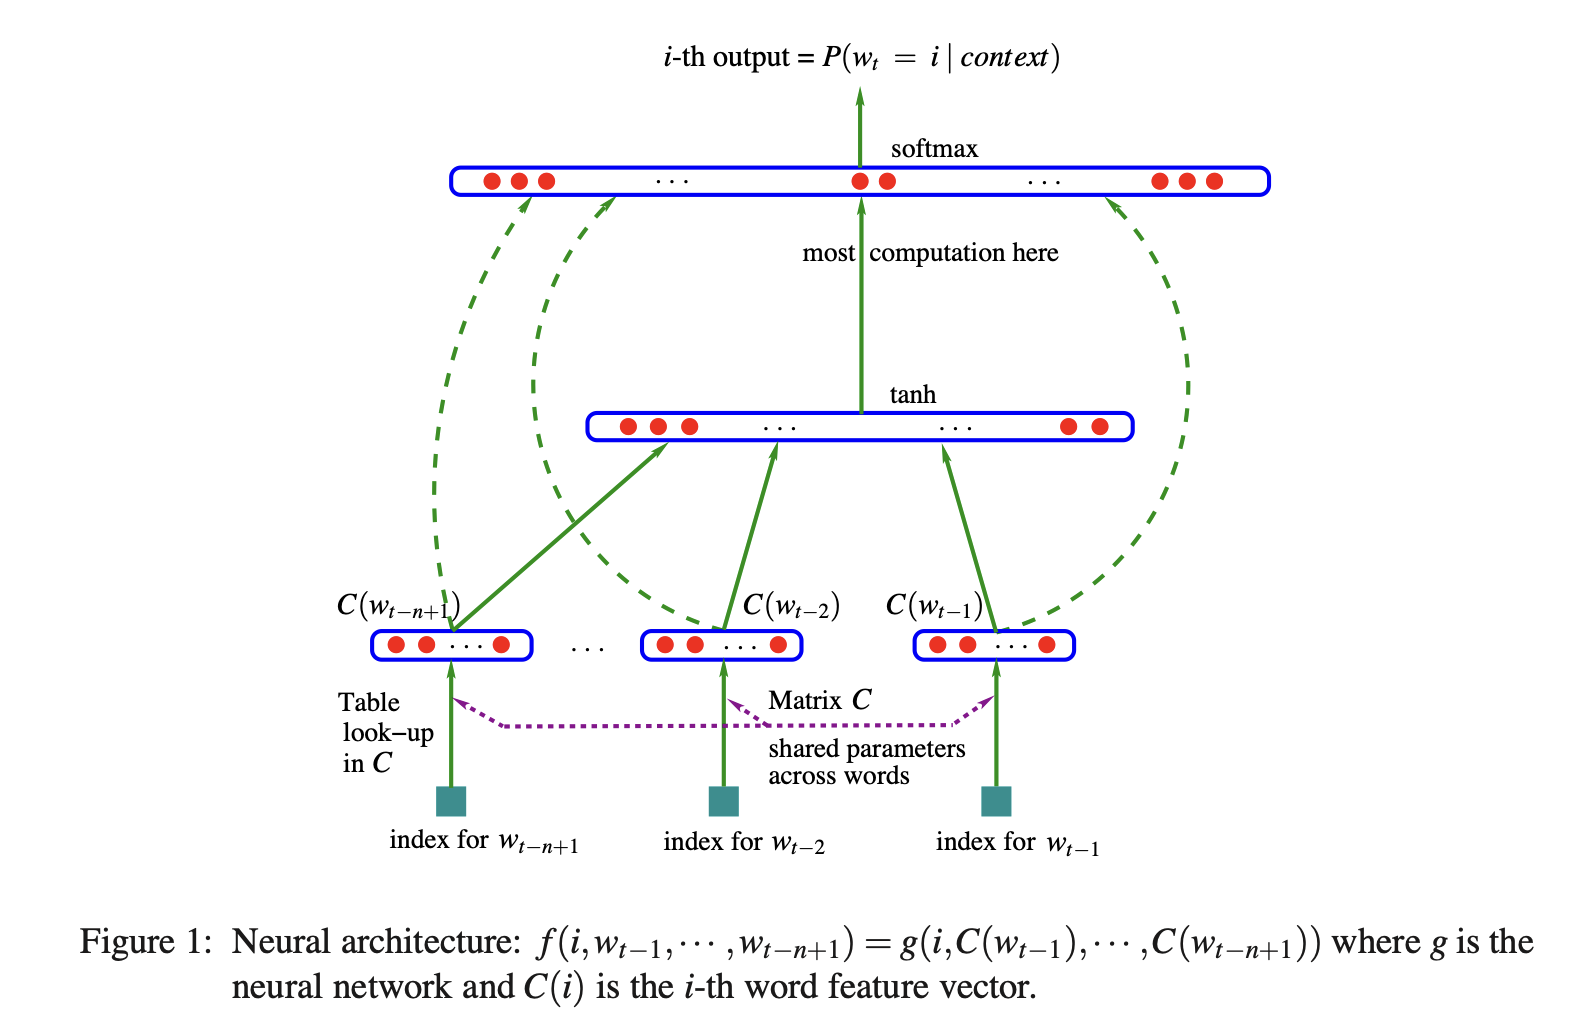

In [21]:
from IPython.display import Image
Image('part2-MLP-architecture.png')

In [24]:
# Lets create Lookup table with 2D vector to store data

C = torch.randn(27,2) 
# 27 is the size of the pool you're looking data from
# 27 rows for each char and each one have a 2D vector to represent where they are


emb = C[Xtr]  # look up the embedding vector for every character index in X
emb.shape   # (228146, 3, 2) — same shape as X, plus the 2D embedding appended per character

torch.Size([182625, 3, 2])

In [25]:
emb[0]
# what emb did is take the normal X data and added 1 dimestion i.e their vector index

tensor([[ 2.6936, -0.6145],
        [ 2.6936, -0.6145],
        [ 2.6936, -0.6145]])

In [ ]:
# Frist Hidden layer
# Lets add first hidden layer

W1 = torch.randn(6,200) # 6 cause we will convert the emb into 22k by 6 i.e 3 * 2
b1 = torch.randn(200) # 1 bias per weight

h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
# ((182625, 6) @ (6, 200) + (200,) → (182625, 200)).

In [29]:
# Output Layer
# This is where we'll do h @ W2 + b2 to get something out of it
# To make H @ w2, we need dimension of their inner dim to be same i.e 200

W2 = torch.randn(200, 27)
b2 = torch.randn(27)

logits = (h @ W2 + b2)
logits.shape

torch.Size([182625, 27])

In [ ]:
# Turn Output into Probabilities

counts = logits.exp()                          # make everything positive
probs = counts / counts.sum(1, keepdim=True)    # normalize each row to sum to 1


# OR
# probs = torch.softmax(logits, dim=1) # dim 1 says what axis to normalize it to, i.e accross first axis


probs.shape

torch.Size([182625, 27])

In [31]:
print(probs[0])
print(probs[0].sum())

tensor([6.2106e-11, 5.9137e-04, 6.6875e-10, 7.2255e-12, 1.6392e-03, 3.8583e-13,
        3.6924e-06, 1.4143e-11, 1.8591e-06, 7.8718e-02, 9.3850e-11, 8.6938e-06,
        3.1285e-01, 9.7220e-12, 6.0618e-01, 8.8979e-09, 5.3773e-29, 2.6927e-11,
        6.6966e-20, 1.7723e-14, 7.2554e-12, 7.5512e-14, 4.9411e-10, 4.0633e-10,
        2.0846e-14, 7.3946e-10, 7.6234e-06])
tensor(1.)


In [36]:
Ytr

tensor([25, 21,  8,  ...,  1, 14,  0])

In [37]:
probs[0,25]

tensor(7.3946e-10)

In [ ]:
# Phase 6: Loss

# Manual version — index out the probability the model gave to the
# actual correct next character (one per example), log it, negate, average.
loss = -probs[torch.arange(182625), Ytr].log().mean()
# NEW: for each index out of 18k, there are 27 column that predicts how much each
# char is predicted, then we find the prediction of the correct prediction.

# Built-in shortcut — does exp/normalize/log internally, takes raw
# logits directly (not probs), more numerically stable for large logits.
loss = F.cross_entropy(logits, Ytr)
loss

tensor(21.6081)

### Real Parameter Setup

In [39]:
# Phase 7: Real parameter setup

g = torch.Generator().manual_seed(2147483647)  # reproducibility

C = torch.randn((27, 10), generator=g)      # embedding_dim: 2 → 10
W1 = torch.randn((30, 200), generator=g)    # 30 = block_size(3) * embedding_dim(10)
b1 = torch.randn(200, generator=g)
W2 = torch.randn((200, 27), generator=g)
b2 = torch.randn(27, generator=g)

parameters = [C, W1, b1, W2, b2]

for p in parameters:
    p.requires_grad = True

sum(p.nelement() for p in parameters)  # total parameter count

11897

In [ ]:
# Phase 8: Training loop with minibatches

for i in range(200000):

    ## minibatch construct
    ix = torch.randint(0, X.shape[0], (32,))  # 32 random row indices, 0 to 228145
    # 0 — the lowest possible value it can generate
    
    # X.shape[0] — the upper bound (exclusive). Since X.shape[0] = 228146, 
    # this means it generates numbers from 0 up to 228145.
    
    # (32,) — the shape of the output. This means "give me a 1D tensor with 32 values."
    
    
    ## forward pass
    emb = C[X[ix]]                                    # (32, 3, 10)
    h = torch.tanh(emb.view(-1, 30) @ W1 + b1)         # (32, 200)
    logits = h @ W2 + b2                               # (32, 27)
    loss = F.cross_entropy(logits, Y[ix])

    ## backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    ## update
    lr = 0.1
    for p in parameters:
        p.data += -lr * p.grad

In [41]:
loss

tensor(2.0304, grad_fn=<NllLossBackward0>)

### Finding a reasonable learning rate (HOW)?

Text(0, 0.5, 'loss')

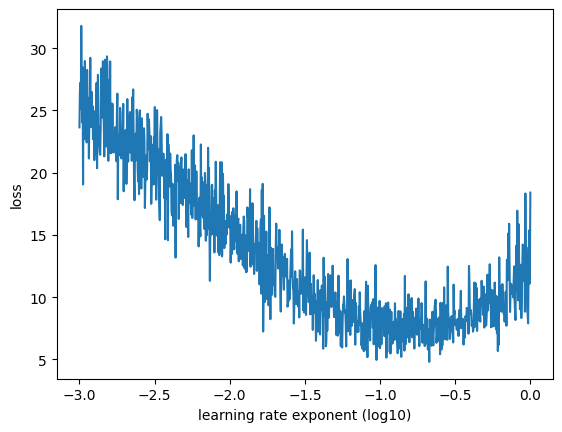

In [42]:
# Phase 9: Finding a reasonable learning rate

lre = torch.linspace(-3, 0, 1000)   # 1000 evenly spaced exponents from -3 to 0
lrs = 10**lre                        # learning rates from 0.001 to 1, spaced exponentially

lri = []
lossi = []

# re-initialize parameters fresh
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, 10), generator=g)
W1 = torch.randn((30, 200), generator=g)
b1 = torch.randn(200, generator=g)
W2 = torch.randn((200, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]
for p in parameters:
    p.requires_grad = True

for i in range(1000):
    # minibatch
    ix = torch.randint(0, X.shape[0], (32,))

    # forward pass
    emb = C[X[ix]]
    h = torch.tanh(emb.view(-1, 30) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Y[ix])

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update — using this iteration's learning rate from the sweep
    lr = lrs[i]
    for p in parameters:
        p.data += -lr * p.grad

    # track
    lri.append(lre[i].item())
    lossi.append(loss.item())

import matplotlib.pyplot as plt
plt.plot(lri, lossi)
plt.xlabel('learning rate exponent (log10)')
plt.ylabel('loss')

**So it can be deduced that -1 or 10^-1 or 0.1 is the ideal learning rate for this workflow

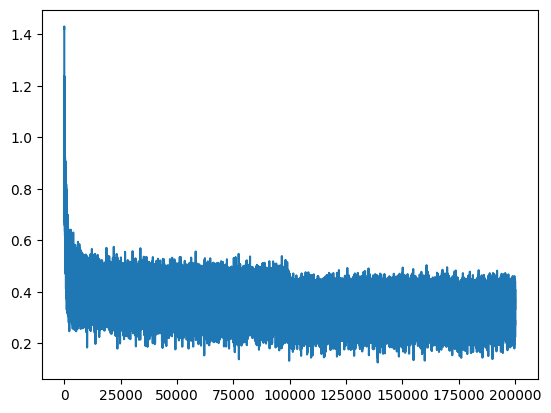

In [45]:
# Phase 10: Real training run with learning rate decay

g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, 10), generator=g)
W1 = torch.randn((30, 200), generator=g)
b1 = torch.randn(200, generator=g)
W2 = torch.randn((200, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]
for p in parameters:
    p.requires_grad = True

stepi = []
lossi = []

for i in range(200000):
    # minibatch
    ix = torch.randint(0, X.shape[0], (32,))

    # forward pass
    emb = C[X[ix]]
    h = torch.tanh(emb.view(-1, 30) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Y[ix])

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update — with decay
    lr = 0.1 if i < 100000 else 0.01
    for p in parameters:
        p.data += -lr * p.grad

    # track
    stepi.append(i)
    lossi.append(loss.log10().item())

plt.plot(stepi, lossi)

In [47]:
loss

tensor(1.9346, grad_fn=<NllLossBackward0>)

In [48]:
# full-batch, no minibatch sampling, no backward pass
with torch.no_grad():
    emb = C[Xtr]
    h = torch.tanh(emb.view(-1, 30) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Ytr)
print("train loss:", loss.item())

emb = C[Xdev]
h = torch.tanh(emb.view(-1, 30) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Ydev)
print("dev loss:", loss.item())

train loss: 2.1394786834716797
dev loss: 2.1374425888061523


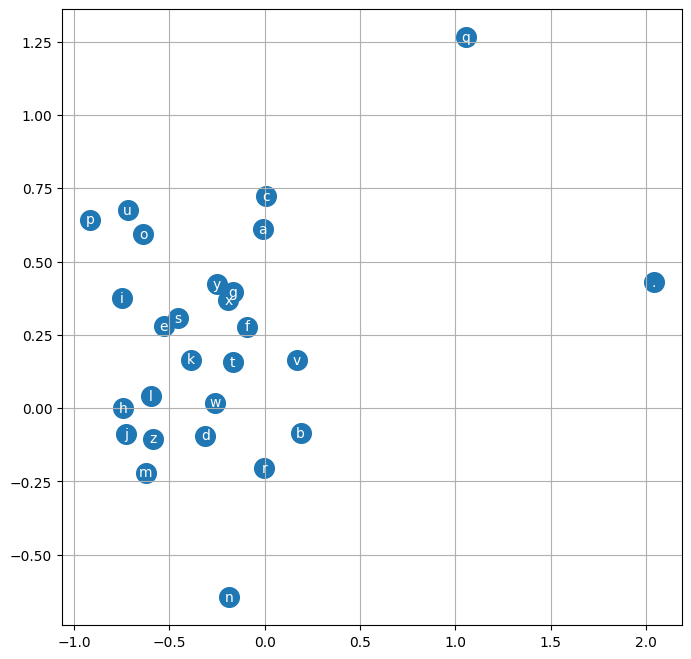

In [49]:
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color='white')
plt.grid('minor')

In [50]:
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
    out = []
    context = [0] * block_size
    while True:
        emb = C[torch.tensor([context])]         # (1, block_size, embedding_dim)
        h = torch.tanh(emb.view(1, -1) @ W1 + b1)
        logits = h @ W2 + b2
        probs = F.softmax(logits, dim=1)
        ix = torch.multinomial(probs, num_samples=1, generator=g).item()
        context = context[1:] + [ix]
        out.append(ix)
        if ix == 0:
            break
    print(''.join(itos[i] for i in out))

carmah.
quille.
khirmir.
rehty.
salaysa.
jazhutt.
den.
rha.
kaeli.
nellara.
chaiivon.
legg.
dham.
pois.
quint.
sulin.
alianni.
watelo.
dearynix.
kael.
